# 유압펌프 이상탐지 — PatchTST 재구성 기반 Anomaly Detection

**과제**: 정상 데이터(`press_data_normal.csv`)만으로 학습한 뒤, 시점(행)별 anomaly score를 계산해 이상 구간(`outlier_data.csv`)을 탐지한다.
**접근**: PatchTST(patch + channel-independent Transformer)를 **마스킹 재구성(masked reconstruction)** 방식으로 학습하고, 재구성 오차를 anomaly score로 사용한다.

## 목차와 서면평가 항목 매핑
| 섹션 | 내용 | 평가 항목 |
|---|---|---|
| 0 | CONFIG · seed · device | 6. 코드 및 재현성 |
| 1 | 데이터 로드 · EDA 문제 진단 요약 | 1. 데이터 이해 및 진단 |
| 2 | 전처리 (중복 → 정렬 → 세그먼트 분리 → 리샘플·보간 → 시간분할 → 정규화 → 윈도우) | 1. 데이터 이해 및 진단 |
| 2-B | 파생 변수 (세그먼트 내부에서만 계산) | 1, 5. 창의성 |
| 3 | PatchTST 모델 (RevIN → Patching → Transformer → Head) | 2. AI 예측모델 개발 |
| 4 | 학습 (early stopping, 학습곡선, 가중치 저장) | 2, 6 |
| 5 | 임계값 결정 (val 분포 기반 vs F1 최대화) | 2, 3 |
| 6 | 베이스라인 비교 (z-score, IsolationForest, PatchTST 원본, PatchTST 원본+파생) | 2. 모델 비교·선정근거 |
| 7 | 결과 분석 (score 시계열, 채널 기여도, 재구성 overlay, 갭 영향, FN/FP 조건) | 3. 영향요인 및 오류분석 |
| 8 | 현장 활용 방안 · 차별화 포인트 | 4, 5 |
| 9 | 제출 파일 생성 · 형식 검증 | 6 |
| 10 | 최종 요약 | 전체 |

> 실행 규칙: 위에서 아래로 한 번에 실행(Run All)하면 전처리 → 학습 → 추론 → 결과 파일 생성까지 자동으로 끝난다. 외부 패키지는 numpy / pandas / torch / sklearn / matplotlib만 사용한다.

## 0. CONFIG · 재현성 설정
목적: 경로·하이퍼파라미터를 한 곳에 모으고, seed를 고정해 같은 환경에서 같은 결과가 나오게 한다.

In [ ]:
import os, random, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, f1_score, precision_score, recall_score
from sklearn.ensemble import IsolationForest

%matplotlib inline
warnings.filterwarnings("ignore")

CONFIG = {
    # ── 경로 ──
    "NORMAL_PATH": "press_data_normal.csv",
    "OUTLIER_PATH": "outlier_data.csv",
    "OUT_DIR": "patchtst_outputs",          # 가중치·그림·제출파일 저장 위치
    # ── 컬럼 ──
    "TIME_COL": "TimeStamp",
    "LABEL_COL": "Equipment_state",
    "CHANNELS": ["AI0_Vibration", "AI1_Vibration", "AI2_Current"],   # 원본 센서 3개
    # ── 전처리 ──
    "NOMINAL_DT": 0.1,       # 명목 샘플링 주기(초). EDA에서 중앙값 0.1s 확인
    "GAP_FACTOR": 10,        # 중앙값의 10배(=1초) 넘는 간격이면 세그먼트를 끊는다
    "MAX_INTERP": 3,         # 이 샘플 수 이하의 짧은 결측만 선형 보간
    "TRAIN_RATIO": 0.8,      # normal 앞 80%를 train, 뒤 20%를 val (시간순)
    # ── 윈도우 ──
    # EDA: 세그먼트(버스트) 최대 길이가 50행(5초)이므로 윈도우는 50 이하여야 한다
    "WINDOW": 32,            # 윈도우 길이(샘플) = 3.2초
    "STRIDE": 4,             # 슬라이딩 간격
    "MIN_SEG_INFER": 8,      # 추론 시 이보다 짧은 세그먼트는 score를 매기지 않는다(패딩 한계)
    # ── 파생 변수 ──
    "use_features": True,    # True: 원본+파생 / False: 원본만  (6절에서 둘 다 비교한다)
    "ROLL_WIN": 10,          # 이동 통계 윈도우(샘플) = 1초
    # ── PatchTST ──
    "PATCH_LEN": 4,          # 패치 길이. (WINDOW-PATCH_LEN) % PATCH_STRIDE == 0 이어야 한다
    "PATCH_STRIDE": 4,       # = PATCH_LEN → 겹치지 않는 패치 (마스킹 시 정보 누출 방지)
    "D_MODEL": 64,           # 데이터 2만 행 → 소형 모델
    "N_HEADS": 4,
    "N_LAYERS": 2,
    "D_FF": 128,
    "DROPOUT": 0.1,
    "MASK_RATIO": 0.4,       # 학습 시 가리는 패치 비율 (PatchTST self-supervised 방식)
    "N_INFER_MASKS": 8,      # 추론 시 서로 다른 마스크 개수 (평균 내어 score 안정화)
    # ── 학습 ──
    "BATCH_SIZE": 64,
    "EPOCHS": 60,
    "LR": 1e-3,
    "PATIENCE": 8,           # val loss가 이 epoch 동안 안 좋아지면 중단
    "SEED": 42,
}
assert (CONFIG["WINDOW"] - CONFIG["PATCH_LEN"]) % CONFIG["PATCH_STRIDE"] == 0, "패치가 윈도우를 정확히 덮어야 한다"
os.makedirs(CONFIG["OUT_DIR"], exist_ok=True)


def set_seed(seed: int) -> None:
    """random / numpy / torch / cuda seed를 모두 고정한다. cudnn도 결정론 모드로 둔다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True   # 같은 입력 → 같은 출력 (속도는 약간 손해)
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["SEED"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

# 그림 색: 정상=파랑, 이상=주황 (고정 순서, 색약 대비 검증된 조합). 임계값/경고=빨강
COLOR = {"normal": "#2a78d6", "outlier": "#eb6834", "thr": "#e34948", "gray": "#9a9a9a", "recon": "#2f9e6f"}
plt.rcParams.update({"axes.unicode_minus": False, "figure.dpi": 100})

torch 2.13.0+cu126 | device: cuda


## 1. 데이터 로드 및 진단 요약
목적: 두 파일의 크기·기간·라벨을 확인하고, EDA에서 찾은 문제가 이 노트북의 어느 셀에서 해결되는지 연결한다.

| EDA에서 발견한 문제 | 모델링에 미치는 영향 | 처리 위치 |
|---|---|---|
| 클래스 불균형 33:1 (정상 20,000 / 이상 600) | 지도학습 불가, Accuracy 무의미 | 정상만으로 학습하는 재구성 방식 (3절), F1/PR-AUC 평가 (5·6절) |
| 50행(5초) 단위 버스트 수집, 사이에 1.5~16초 갭 | 갭을 가로지르는 윈도우는 가짜 시계열 | 세그먼트 분리 (2-3), 세그먼트 내부 윈도우 (2-7) |
| 동일 타임스탬프 중복 행 1건 | 최소 간격 0초, 통계 왜곡 | 2-1 |
| 정상 내부 저진폭 운전 구간 (01:00~01:12) | 정상 분포가 둘로 갈림 → 오탐 원인 | 7-5 오류 조건 분석에서 별도 표시 |
| 전류가 정류되지 않은 교류 파형 (평균≈0) | 평균/최대 같은 단순 통계 무의미 | 파생 변수: 이동 RMS (2-B) |
| 정상/이상 파일이 다른 날짜·조건 | 조건 차이를 이상으로 오인할 위험 | 절대값 대신 윈도우 내부 정규화(RevIN, 3절) |

In [ ]:
def load_raw(path: str, cfg: dict) -> pd.DataFrame:
    """csv를 읽고 인덱스 컬럼 제거, 시간 컬럼을 datetime으로 변환한다."""
    df = pd.read_csv(path)
    unnamed = [c for c in df.columns if str(c).startswith("Unnamed")]   # 저장 시 섞인 인덱스 컬럼
    df = df.drop(columns=unnamed)
    df[cfg["TIME_COL"]] = pd.to_datetime(df[cfg["TIME_COL"]])
    return df


raw_normal = load_raw(CONFIG["NORMAL_PATH"], CONFIG)
raw_outlier = load_raw(CONFIG["OUTLIER_PATH"], CONFIG)

for name, df in [("normal", raw_normal), ("outlier", raw_outlier)]:
    tc = CONFIG["TIME_COL"]
    print(f"[{name}] shape={df.shape} | 기간 {df[tc].min()} ~ {df[tc].max()} "
          f"| 라벨 분포 {df[CONFIG['LABEL_COL']].value_counts().to_dict()}")

# 파일 자체가 라벨이다: normal 파일 = 전부 0, outlier 파일 = 전부 1 → 행 단위 라벨은 파일 단위 라벨과 같다
print(f"\n불균형 비율: {len(raw_normal)} : {len(raw_outlier)} = {len(raw_normal)/len(raw_outlier):.1f} : 1")

[normal] shape=(20000, 5) | 기간 2022-07-12 00:00:00.019000 ~ 2022-07-12 01:16:55.828000 | 라벨 분포 {0: 20000}
[outlier] shape=(600, 5) | 기간 2022-07-17 10:51:07.943000 ~ 2022-07-17 10:53:53.540000 | 라벨 분포 {1: 600}

불균형 비율: 20000 : 600 = 33.3 : 1


## 2. 전처리
각 단계는 "왜 필요한가"를 먼저 적고, 처리 전/후 수치를 출력해 효과를 확인한다.

### 2-1. 동일 타임스탬프 행 처리
**왜**: 같은 시각에 두 행이 있으면 간격이 0초가 되어 리샘플링이 깨지고, 완전 중복이면 같은 샘플이 두 번 학습된다.
- 값까지 같은 **완전 중복** → 한 행만 남긴다.
- 시각만 같고 값이 다른 **충돌** → 두 값의 평균으로 병합한다 (같은 순간의 두 측정치라고 보는 것이 가장 보수적).
어느 케이스인지는 코드로 판별해 출력한다.

In [ ]:
def resolve_duplicate_timestamps(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """동일 타임스탬프 행을 판별(완전 중복 / 값 충돌)하고 제거 또는 평균 병합한다."""
    tc, chs = cfg["TIME_COL"], cfg["CHANNELS"]
    n_ts_dup = int(df[tc].duplicated().sum())                 # 시각이 같은 '추가' 행 수
    n_full_dup = int(df.duplicated(subset=[tc] + chs).sum())  # 시각+값이 모두 같은 추가 행 수
    n_conflict = n_ts_dup - n_full_dup                        # 시각만 같고 값이 다른 행 수
    print(f"  동일 시각 행: {n_ts_dup}건 → 완전 중복 {n_full_dup}건 (제거), 값 충돌 {n_conflict}건 (평균 병합)")

    before = len(df)
    df = df.drop_duplicates(subset=[tc] + chs)                          # 완전 중복 제거
    df = df.groupby(tc, as_index=False)[chs].mean()                     # 남은 동일 시각은 평균 병합
    print(f"  행 수: {before} → {len(df)}")
    return df


print("[normal]");  normal_p = resolve_duplicate_timestamps(raw_normal, CONFIG)
print("[outlier]"); outlier_p = resolve_duplicate_timestamps(raw_outlier, CONFIG)

[normal]
  동일 시각 행: 1건 → 완전 중복 1건 (제거), 값 충돌 0건 (평균 병합)
  행 수: 20000 → 19999
[outlier]
  동일 시각 행: 0건 → 완전 중복 0건 (제거), 값 충돌 0건 (평균 병합)
  행 수: 600 → 600


### 2-2. 시간순 정렬 후 인덱스 초기화
**왜**: 이후 모든 처리(간격 계산, 세그먼트 분리, 윈도우)는 "행 순서 = 시간 순서"를 가정한다. 인덱스를 0부터 다시 매겨야 위치 기반 인덱싱(`iloc`, numpy)과 라벨 인덱스가 어긋나지 않는다.

In [ ]:
def sort_by_time(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """시간순 정렬 + reset_index. 정렬 전후로 순서가 바뀐 행 수를 출력한다."""
    tc = cfg["TIME_COL"]
    n_unsorted = int((df[tc].diff().dt.total_seconds() < 0).sum())   # 시간이 거꾸로 가는 지점 수
    df = df.sort_values(tc).reset_index(drop=True)
    print(f"  시간 역행 지점 {n_unsorted}건 → 정렬 완료, 행 {len(df)}")
    return df


print("[normal]");  normal_p = sort_by_time(normal_p, CONFIG)
print("[outlier]"); outlier_p = sort_by_time(outlier_p, CONFIG)

[normal]
  시간 역행 지점 0건 → 정렬 완료, 행 19999
[outlier]
  시간 역행 지점 0건 → 정렬 완료, 행 600


### 2-3. 큰 갭에서 세그먼트 분리
**왜**: 이 데이터는 0.1초 간격으로 최대 50행을 수집한 뒤 1.5~16초를 쉬는 **버스트 구조**다. 갭을 무시하고 윈도우를 자르면, 실제로는 10초 떨어진 두 순간이 "연속된 0.1초"처럼 붙는다.
- 그 경계에서 값이 점프한 것처럼 보여 **가짜 이상**이 생기고
- 정상 데이터로 학습할 때는 그런 점프를 "정상"으로 배워 **진짜 이상에 둔감**해진다.

따라서 중앙값 간격의 `GAP_FACTOR`배(=1초)를 넘는 지점마다 시계열을 끊어 독립된 세그먼트로 다룬다. 윈도우·이동통계·차분은 모두 세그먼트 안에서만 계산한다.

In [ ]:
def assign_segments(df: pd.DataFrame, cfg: dict, gap_sec: float, verbose: bool = True) -> pd.DataFrame:
    """앞 행과의 간격이 gap_sec를 넘는 지점마다 seg_id를 1씩 올려 세그먼트를 나눈다."""
    tc = cfg["TIME_COL"]
    dt = df[tc].diff().dt.total_seconds().fillna(0.0)
    df = df.copy()
    df["seg_id"] = (dt > gap_sec).cumsum().astype(int)
    if verbose:
        seg_len = df.groupby("seg_id").size()
        gaps = dt[dt > gap_sec]
        print(f"  갭 기준 {gap_sec:.2f}s | 세그먼트 {len(seg_len)}개 | 길이 min/median/max = "
              f"{seg_len.min()}/{int(seg_len.median())}/{seg_len.max()}행 | "
              f"갭 크기 min/median/max = {gaps.min():.2f}/{gaps.median():.2f}/{gaps.max():.2f}s")
    return df


GAP_SEC = CONFIG["NOMINAL_DT"] * CONFIG["GAP_FACTOR"]
print("[normal]");  normal_p = assign_segments(normal_p, CONFIG, GAP_SEC)
print("[outlier]"); outlier_p = assign_segments(outlier_p, CONFIG, GAP_SEC)

[normal]
  갭 기준 1.00s | 세그먼트 599개 | 길이 min/median/max = 1/37/50행 | 갭 크기 min/median/max = 1.54/4.22/16.64s
[outlier]
  갭 기준 1.00s | 세그먼트 21개 | 길이 min/median/max = 3/28/50행 | 갭 크기 min/median/max = 1.78/5.35/8.57s


### 2-4. 세그먼트 내부 0.1초 격자 리샘플 + 짧은 결측만 보간
**왜**: 모델은 "샘플 하나 = 0.1초"라는 등간격을 가정한다. 세그먼트 안에서 시각을 0.1초 격자에 스냅하고, 빠진 샘플이 `MAX_INTERP`(3개) 이하이면 선형 보간한다. 그보다 긴 결측은 값을 지어내는 것이므로 보간하지 않고 그 자리에서 세그먼트를 다시 끊는다.
보간된 행은 `is_interp` 마스크로 남겨, 7절에서 "탐지된 이상이 보간 때문인지"를 확인할 수 있게 한다.

In [ ]:
def resample_segments(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """세그먼트별로 0.1초 격자에 맞추고, 짧은 결측만 선형 보간한다. 긴 결측은 삭제한다."""
    tc, chs, dt, max_interp = cfg["TIME_COL"], cfg["CHANNELS"], cfg["NOMINAL_DT"], cfg["MAX_INTERP"]
    out, n_interp, n_dropped, n_snap = [], 0, 0, 0
    for sid, seg in df.groupby("seg_id"):
        t0 = seg[tc].iloc[0]
        k = np.round((seg[tc] - t0).dt.total_seconds() / dt).astype(int)   # 격자 위치(정수)
        seg = seg.assign(k=k.values)
        g = seg.groupby("k")[chs].mean()                # 같은 격자로 스냅된 행은 평균
        g[tc] = seg.groupby("k")[tc].first()            # 실제 행은 원래 시각을 유지(제출 시 병합 키)
        n_snap += len(seg) - len(g)
        g = g.reindex(pd.RangeIndex(0, int(g.index.max()) + 1))   # 빠진 격자를 NaN 행으로 채움
        is_real = g[chs[0]].notna()
        # 결측 run 길이를 계산해 짧은 run만 보간 대상으로 표시
        isna = ~is_real
        run_id = (isna != isna.shift()).cumsum()
        run_len = isna.groupby(run_id).transform("size")
        fill_ok = isna & (run_len <= max_interp)
        interp = g[chs].interpolate("linear", limit_area="inside")
        g.loc[fill_ok, chs] = interp.loc[fill_ok, chs]
        n_interp += int(fill_ok.sum())
        still_na = g[chs[0]].isna()
        n_dropped += int(still_na.sum())
        g = g[~still_na].copy()
        # 보간된 행의 시각은 격자 시각으로 채운다
        grid_time = t0 + pd.to_timedelta(np.round(g.index.values * dt, 3), unit="s")
        g[tc] = g[tc].fillna(pd.Series(grid_time, index=g.index))
        g["is_interp"] = ~is_real[g.index]
        out.append(g[[tc] + chs + ["is_interp"]])
    res = pd.concat(out, ignore_index=True)
    print(f"  행 {len(df)} → {len(res)} | 같은 격자로 병합 {n_snap}행 | 보간 {n_interp}행 | 긴 결측으로 삭제 {n_dropped}격자")
    # 보간되지 않은 긴 결측이 남긴 틈에서 세그먼트를 다시 끊는다(2차 분리)
    res = assign_segments(res, cfg, gap_sec=dt * 1.5, verbose=True)
    return res


print("[normal]");  normal_p = resample_segments(normal_p, CONFIG)
print("[outlier]"); outlier_p = resample_segments(outlier_p, CONFIG)

# 파일 = 라벨 (normal 0, outlier 1)
normal_p["y"] = 0
outlier_p["y"] = 1

# 리샘플 결과 확인: 세그먼트 안의 간격은 전부 0.1초여야 한다
for name, df in [("normal", normal_p), ("outlier", outlier_p)]:
    d = df.groupby("seg_id")[CONFIG["TIME_COL"]].diff().dt.total_seconds().dropna()
    print(f"  {name}: 세그먼트 내부 간격 종류 = {sorted(d.round(3).unique())}")

[normal]


  행 19999 → 19999 | 같은 격자로 병합 0행 | 보간 0행 | 긴 결측으로 삭제 0격자
  갭 기준 0.15s | 세그먼트 599개 | 길이 min/median/max = 1/37/50행 | 갭 크기 min/median/max = 1.54/4.22/16.64s
[outlier]
  행 600 → 600 | 같은 격자로 병합 0행 | 보간 0행 | 긴 결측으로 삭제 0격자
  갭 기준 0.15s | 세그먼트 21개 | 길이 min/median/max = 3/28/50행 | 갭 크기 min/median/max = 1.78/5.35/8.57s
  normal: 세그먼트 내부 간격 종류 = [0.1]
  outlier: 세그먼트 내부 간격 종류 = [0.1]


### 2-5. normal을 시간 기준으로 train / val 분리
**왜 랜덤 분할이 안 되는가**: 슬라이딩 윈도우는 서로 겹치므로, 랜덤으로 나누면 train 윈도우와 val 윈도우가 같은 구간을 공유한다. val 오차가 실제보다 낮게 나와 임계값이 너무 낮게 잡히고, 실제 운전 데이터에서 오탐이 급증한다. 시간 순으로 앞 80%를 train, 뒤 20%를 val로 두되, 경계는 **세그먼트 시작점으로 옮겨** 한 세그먼트가 양쪽에 걸치지 않게 한다.

In [ ]:
def time_split(df: pd.DataFrame, ratio: float) -> pd.DataFrame:
    """앞 ratio 비율은 train, 나머지는 val. 경계를 다음 세그먼트 시작으로 이동한다."""
    df = df.copy()
    target = int(len(df) * ratio)
    seg_starts = df.index[df["seg_id"] != df["seg_id"].shift()]      # 각 세그먼트의 첫 행 위치
    split_at = int(seg_starts[seg_starts >= target][0])
    df["split"] = np.where(df.index < split_at, "train", "val")
    tc = CONFIG["TIME_COL"]
    for s in ["train", "val"]:
        part = df[df["split"] == s]
        print(f"  {s}: {len(part)}행, {part['seg_id'].nunique()}세그먼트, {part[tc].min().time()} ~ {part[tc].max().time()}")
    return df


normal_p = time_split(normal_p, CONFIG["TRAIN_RATIO"])
outlier_p["split"] = "test"

  train: 16009행, 481세그먼트, 00:00:00.019000 ~ 01:01:01.732000
  val: 3990행, 118세그먼트, 01:01:04.524000 ~ 01:16:55.828000


### 2-B. 파생 변수 (feature engineering)
원본 센서 3개에 더해, 아래 파생 변수를 **세그먼트 안에서만** 계산한다. 갭 앞뒤 값을 섞어 차분·이동통계를 내면 10초 떨어진 두 값의 차이가 "0.1초 사이의 급변"으로 기록되어 세그먼트 경계마다 가짜 이상이 생긴다. 아래 셀에서 이를 수치로 확인한다.

| 파생 변수 | 잡으려는 이상 패턴 |
|---|---|
| `*_diff` (1차 차분) | 진동·전류의 **급격한 변화율** — EDA에서 이상 데이터의 첨도(kurtosis)가 크게 늘어 충격성 신호가 의심됨 |
| `*_rstd` (이동 표준편차, 1초) | **국소 분산 확대** — 이상 데이터의 AI0 std가 정상의 6배 |
| `AI2_Current_rms` (이동 RMS, 1초) | 전류는 교류 파형이라 평균이 0 → **진폭(부하) 변화**는 RMS로만 보인다. 이상 데이터의 RMS가 122 → 163으로 상승 |

**넣지 않은 후보**: 실제 샘플링 간격(dt)은 리샘플 후 세그먼트 안에서 항상 0.1초로 상수가 되어 정보가 없다. 갭 정보는 대신 세그먼트 경계와 `is_interp` 마스크로 보존한다.

In [ ]:
FEATURE_COLS = []   # 파생 변수 이름 목록 (아래에서 채움)


def add_features(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """세그먼트 내부에서만 차분 / 이동 std / 전류 이동 RMS를 계산한다."""
    df = df.copy()
    g = df.groupby("seg_id")
    w = cfg["ROLL_WIN"]
    cols = []
    for ch in cfg["CHANNELS"]:
        df[f"{ch}_diff"] = g[ch].diff().fillna(0.0)                                          # 세그먼트 첫 행은 0
        df[f"{ch}_rstd"] = g[ch].transform(lambda s: s.rolling(w, min_periods=2).std()).fillna(0.0)
        cols += [f"{ch}_diff", f"{ch}_rstd"]
    df["AI2_Current_rms"] = g["AI2_Current"].transform(lambda s: np.sqrt((s ** 2).rolling(w, min_periods=1).mean()))
    cols.append("AI2_Current_rms")
    return df, cols


normal_p, FEATURE_COLS = add_features(normal_p, CONFIG)
outlier_p, _ = add_features(outlier_p, CONFIG)
print("파생 변수:", FEATURE_COLS)

# 세그먼트 경계를 무시하고 차분하면 어떤 일이 생기는지 확인
naive_diff = normal_p["AI2_Current"].diff().abs()                     # 경계 무시
seg_diff = normal_p["AI2_Current_diff"].abs()                          # 세그먼트 내부
boundary = normal_p["seg_id"] != normal_p["seg_id"].shift()
print(f"경계 무시 차분의 99.9% 분위: 내부 {seg_diff.quantile(0.999):.1f} vs 경계에서 {naive_diff[boundary].quantile(0.999):.1f}"
      f" → 경계 행 {int(boundary.sum())}개가 가짜 급변으로 잡힌다")

파생 변수: ['AI0_Vibration_diff', 'AI0_Vibration_rstd', 'AI1_Vibration_diff', 'AI1_Vibration_rstd', 'AI2_Current_diff', 'AI2_Current_rstd', 'AI2_Current_rms']
경계 무시 차분의 99.9% 분위: 내부 94.2 vs 경계에서 460.6 → 경계 행 599개가 가짜 급변으로 잡힌다


### 2-6. 정규화 — normal의 train 통계만 사용
**왜 outlier 통계가 새면 안 되는가**: 정규화 mean/std에 outlier가 섞이면 (1) 이상 데이터가 정규화 후 "평범한" 범위로 눌려 탐지 감도가 떨어지고, (2) 실제 운영에서는 아직 보지 못한 이상 데이터의 통계를 미리 알 수 없으므로 평가가 실제보다 낙관적이 된다(데이터 누수). val 통계도 같은 이유로 제외한다.

In [ ]:
def fit_stats(df: pd.DataFrame, cols: list) -> tuple:
    """train 행에서만 mean/std를 계산한다. std가 0인 컬럼은 나눗셈 보호."""
    mu = df[cols].mean()
    sd = df[cols].std().clip(lower=1e-6)
    return mu, sd


def apply_norm(df: pd.DataFrame, cols: list, mu, sd) -> np.ndarray:
    """(x - mu) / sd → float32 배열 [N, C]"""
    return ((df[cols] - mu) / sd).to_numpy(dtype=np.float32)


ALL_COLS = CONFIG["CHANNELS"] + FEATURE_COLS
train_rows = normal_p[normal_p["split"] == "train"]
MU, SD = fit_stats(train_rows, ALL_COLS)
print("train 통계 (원본 채널만 표시):")
print(pd.DataFrame({"mean": MU, "std": SD}).loc[CONFIG["CHANNELS"]].round(4))

# 통계 누수 검증: outlier로 정규화한 값과 train으로 정규화한 값의 스케일 차이
mu_leak, sd_leak = fit_stats(outlier_p, CONFIG["CHANNELS"])
print("\n만약 outlier 통계로 정규화했다면 |z| 평균:",
      ((outlier_p[CONFIG["CHANNELS"]] - mu_leak) / sd_leak).abs().mean().round(2).to_dict())
print("train 통계로 정규화한 outlier |z| 평균   :",
      ((outlier_p[CONFIG["CHANNELS"]] - MU[CONFIG["CHANNELS"]]) / SD[CONFIG["CHANNELS"]]).abs().mean().round(2).to_dict())

train 통계 (원본 채널만 표시):
                 mean       std
AI0_Vibration -0.0001    0.0743
AI1_Vibration -0.0000    0.1277
AI2_Current    1.2750  127.7931

만약 outlier 통계로 정규화했다면 |z| 평균: {'AI0_Vibration': 0.62, 'AI1_Vibration': 0.78, 'AI2_Current': 0.77}
train 통계로 정규화한 outlier |z| 평균   : {'AI0_Vibration': 3.75, 'AI1_Vibration': 1.47, 'AI2_Current': 0.99}


### 2-7. 세그먼트별 슬라이딩 윈도우
**규칙**
- 윈도우는 세그먼트 안에서만 만든다. 세그먼트 길이 < WINDOW 이면 학습에서는 버린다(버린 개수 출력).
- 추론에서는 모든 행에 score가 필요하므로, 짧은 세그먼트(`MIN_SEG_INFER` 이상)는 마지막 값을 반복해 WINDOW까지 **패딩**하고 실제 행 위치만 score에 반영한다. 패딩 위치는 인덱스 -1로 표시한다.
- 세그먼트 끝이 stride 때문에 덮이지 않으면, 끝에 맞춘 윈도우 하나를 추가한다(커버리지 보장).

In [ ]:
def make_windows(df: pd.DataFrame, Z: np.ndarray, cfg: dict, pad_short: bool, verbose: bool = True):
    """세그먼트 안에서 슬라이딩 윈도우를 만든다.
    반환: X [n, W, C] (정규화 값), IDX [n, W] (df 행 위치, 패딩은 -1)"""
    W, S, min_len = cfg["WINDOW"], cfg["STRIDE"], cfg["MIN_SEG_INFER"]
    X, IDX = [], []
    n_drop_seg = n_drop_rows = n_pad_seg = 0
    for sid, pos in df.groupby("seg_id").indices.items():     # pos: 이 세그먼트 행들의 위치 배열
        L = len(pos)
        if L >= W:
            starts = list(range(0, L - W + 1, S))
            if starts[-1] != L - W:
                starts.append(L - W)                            # 끝 맞춤 윈도우
            for s in starts:
                X.append(Z[pos[s:s + W]]); IDX.append(pos[s:s + W])
        elif pad_short and L >= min_len:
            pad = W - L
            X.append(np.concatenate([Z[pos], np.repeat(Z[pos[-1:]], pad, axis=0)]))   # 마지막 값 반복
            IDX.append(np.concatenate([pos, -np.ones(pad, dtype=int)]))
            n_pad_seg += 1
        else:
            n_drop_seg += 1; n_drop_rows += L
    X = np.stack(X).astype(np.float32); IDX = np.stack(IDX)
    if verbose:
        print(f"  윈도우 {len(X)}개 (shape {X.shape}) | 패딩 세그먼트 {n_pad_seg}개 | "
              f"버린 세그먼트 {n_drop_seg}개 ({n_drop_rows}행)")
    return X, IDX


def build_dataset(cols: list):
    """정규화 → 윈도우 생성까지. 학습용(train만, 패딩 없음)과 추론용(전체, 패딩 허용)을 함께 만든다."""
    Z_n = apply_norm(normal_p, cols, MU[cols], SD[cols])
    Z_o = apply_norm(outlier_p, cols, MU[cols], SD[cols])
    print(" [학습용 normal]");  X_all, IDX_all = make_windows(normal_p, Z_n, CONFIG, pad_short=False)
    split_arr = normal_p["split"].to_numpy()
    is_train = np.all(split_arr[IDX_all] == "train", axis=1)      # 윈도우 전체가 train에 속해야 함
    is_val = np.all(split_arr[IDX_all] == "val", axis=1)
    print(f"   → train 윈도우 {is_train.sum()}개, val 윈도우 {is_val.sum()}개, 경계 걸침 {(~is_train & ~is_val).sum()}개")
    print(" [추론용 normal]");  Xn_inf, IDXn_inf = make_windows(normal_p, Z_n, CONFIG, pad_short=True)
    print(" [추론용 outlier]"); Xo_inf, IDXo_inf = make_windows(outlier_p, Z_o, CONFIG, pad_short=True)
    return {"cols": cols, "X_train": X_all[is_train], "X_val": X_all[is_val],
            "Xn_inf": Xn_inf, "IDXn_inf": IDXn_inf, "Xo_inf": Xo_inf, "IDXo_inf": IDXo_inf}


DATA = {"raw": build_dataset(CONFIG["CHANNELS"]),
        "raw+feat": build_dataset(ALL_COLS)}

 [학습용 normal]
  윈도우 1711개 (shape (1711, 32, 3)) | 패딩 세그먼트 0개 | 버린 세그먼트 249개 (3970행)
   → train 윈도우 1373개, val 윈도우 338개, 경계 걸침 0개
 [추론용 normal]
  윈도우 1911개 (shape (1911, 32, 3)) | 패딩 세그먼트 200개 | 버린 세그먼트 49개 (190행)
 [추론용 outlier]
  윈도우 53개 (shape (53, 32, 3)) | 패딩 세그먼트 9개 | 버린 세그먼트 3개 (11행)
 [학습용 normal]
  윈도우 1711개 (shape (1711, 32, 10)) | 패딩 세그먼트 0개 | 버린 세그먼트 249개 (3970행)
   → train 윈도우 1373개, val 윈도우 338개, 경계 걸침 0개
 [추론용 normal]
  윈도우 1911개 (shape (1911, 32, 10)) | 패딩 세그먼트 200개 | 버린 세그먼트 49개 (190행)
 [추론용 outlier]
  윈도우 53개 (shape (53, 32, 10)) | 패딩 세그먼트 9개 | 버린 세그먼트 3개 (11행)


## 3. PatchTST 모델
목적: 외부 라이브러리 없이 PatchTST의 핵심 구조를 구현하고, **마스킹 재구성**으로 이상 점수를 만든다.

구조: `RevIN(윈도우별 정규화) → Patching → 채널 독립 Transformer Encoder → 재구성 Head → RevIN 역변환`

**왜 마스킹인가**: 윈도우를 그대로 입력해 그대로 복원하도록 학습하면, 병목이 없는 Transformer는 입력을 복사하는 항등 함수를 배울 수 있다. 그러면 이상 윈도우도 잘 복원해 오차가 작아진다. PatchTST의 self-supervised 방식처럼 패치 일부(40%)를 가리고 **주변 패치로부터 맞히게** 하면, 정상 패턴만 배운 모델은 이상 패턴을 맞히지 못해 오차가 커진다.

**왜 채널 독립인가**: 채널마다 별도 시퀀스로 처리하면 (1) 파라미터를 공유해 데이터 2만 행으로도 과적합이 덜하고, (2) 채널별 재구성 오차를 그대로 얻어 "어느 센서가 원인인지" 설명할 수 있다.

**모델 크기**: d_model 64, layer 2 (파라미터 약 8만 개). train 윈도우가 수천 개뿐이므로 큰 모델은 외운다. Dropout 0.1과 early stopping을 함께 쓴다.

In [ ]:
class RevIN(nn.Module):
    """Reversible Instance Normalization.
    윈도우마다 채널별 mean/std로 정규화하고, 출력에서 되돌린다.
    → 정상/이상이 다른 날짜·부하에서 수집되어 생기는 '절대 수준 차이'를 제거하고 파형(형태)만 보게 한다.
    입력 [B, L, C] → 출력 [B, L, C]"""
    def __init__(self, n_ch: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = nn.Parameter(torch.ones(n_ch))    # 채널별 학습 가능한 scale
        self.beta = nn.Parameter(torch.zeros(n_ch))    # 채널별 학습 가능한 shift

    def forward(self, x: torch.Tensor, mode: str) -> torch.Tensor:
        if mode == "norm":
            self.mean = x.mean(dim=1, keepdim=True).detach()                        # [B, 1, C]
            self.std = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + self.eps).detach()
            return (x - self.mean) / self.std * self.gamma + self.beta
        elif mode == "denorm":
            return (x - self.beta) / (self.gamma + self.eps) * self.std + self.mean
        raise ValueError(mode)


class Patching(nn.Module):
    """[B, L, C] → [B*C, N, P]  (N = 패치 수, P = 패치 길이). 채널을 배치 차원으로 합쳐 채널 독립 처리."""
    def __init__(self, patch_len: int, stride: int):
        super().__init__()
        self.P, self.S = patch_len, stride

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, L, C = x.shape
        x = x.permute(0, 2, 1)                              # [B, C, L]
        x = x.unfold(dimension=2, size=self.P, step=self.S) # [B, C, N, P]
        return x.reshape(B * C, x.shape[2], self.P)         # [B*C, N, P]


class PatchTSTReconstructor(nn.Module):
    """마스킹 재구성용 PatchTST.
    forward(x [B, L, C], patch_mask [B*C, N] or None) → 재구성 x_hat [B, L, C]"""
    def __init__(self, n_ch: int, cfg: dict):
        super().__init__()
        L, P, S, D = cfg["WINDOW"], cfg["PATCH_LEN"], cfg["PATCH_STRIDE"], cfg["D_MODEL"]
        self.n_ch, self.L, self.P, self.S = n_ch, L, P, S
        self.N = (L - P) // S + 1                            # 패치 수
        self.revin = RevIN(n_ch)
        self.patching = Patching(P, S)
        self.proj = nn.Linear(P, D)                          # 패치 → 임베딩  [B*C, N, P] → [B*C, N, D]
        self.pos = nn.Parameter(torch.randn(1, self.N, D) * 0.02)   # 학습 가능한 위치 임베딩
        self.mask_token = nn.Parameter(torch.zeros(1, 1, D))        # 가려진 패치 자리에 넣는 토큰
        layer = nn.TransformerEncoderLayer(d_model=D, nhead=cfg["N_HEADS"], dim_feedforward=cfg["D_FF"],
                                           dropout=cfg["DROPOUT"], batch_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, num_layers=cfg["N_LAYERS"])
        self.head = nn.Sequential(nn.Flatten(start_dim=1), nn.Dropout(cfg["DROPOUT"]),
                                  nn.Linear(self.N * D, L))   # [B*C, N*D] → [B*C, L]

    def forward(self, x: torch.Tensor, patch_mask: torch.Tensor = None) -> torch.Tensor:
        B, L, C = x.shape
        x = self.revin(x, "norm")                             # [B, L, C]
        p = self.patching(x)                                  # [B*C, N, P]
        z = self.proj(p) + self.pos                           # [B*C, N, D]
        if patch_mask is not None:                            # 가려진 패치의 임베딩을 mask_token으로 교체
            m = patch_mask.unsqueeze(-1).bool()               # [B*C, N, 1]
            z = torch.where(m, self.mask_token.expand_as(z), z)
        z = self.encoder(z)                                   # [B*C, N, D]
        out = self.head(z)                                    # [B*C, L]
        out = out.view(B, C, L).permute(0, 2, 1)              # [B, L, C]
        return self.revin(out, "denorm")

    def patch_to_pos_mask(self, patch_mask: torch.Tensor, B: int) -> torch.Tensor:
        """패치 마스크 [B*C, N] → 위치 마스크 [B, L, C] (가려진 패치가 덮는 시점은 1)"""
        BC, N = patch_mask.shape
        pos = torch.zeros(BC, self.L, device=patch_mask.device)
        for n in range(N):
            seg = pos[:, n * self.S: n * self.S + self.P]
            pos[:, n * self.S: n * self.S + self.P] = torch.maximum(seg, patch_mask[:, n:n + 1])
        return pos.view(B, self.n_ch, self.L).permute(0, 2, 1)


def random_patch_mask(BC: int, N: int, ratio: float, gen: torch.Generator, device) -> torch.Tensor:
    """시퀀스마다 round(ratio*N)개의 패치를 무작위로 가린다. 반환 [BC, N] float(1=가림)"""
    k = max(1, int(round(ratio * N)))
    order = torch.rand(BC, N, generator=gen).argsort(dim=1)
    mask = torch.zeros(BC, N)
    mask.scatter_(1, order[:, :k], 1.0)
    return mask.to(device)


# 모델 크기 확인
_tmp = PatchTSTReconstructor(n_ch=len(ALL_COLS), cfg=CONFIG)
n_params = sum(p.numel() for p in _tmp.parameters())
print(f"패치 수 N = {_tmp.N}, 파라미터 수 = {n_params:,}")
with torch.no_grad():   # shape 확인용 더미 forward
    xb = torch.randn(2, CONFIG["WINDOW"], len(ALL_COLS))
    mk = random_patch_mask(2 * len(ALL_COLS), _tmp.N, CONFIG["MASK_RATIO"], torch.Generator().manual_seed(0), "cpu")
    print("입력", tuple(xb.shape), "→ 출력", tuple(_tmp(xb, mk).shape), "| 위치 마스크", tuple(_tmp.patch_to_pos_mask(mk, 2).shape))
del _tmp

패치 수 N = 8, 파라미터 수 = 84,276
입력 (2, 32, 10) → 출력 (2, 32, 10) | 위치 마스크 (2, 32, 10)


## 4. 학습
목적: normal train 윈도우로 마스킹 재구성을 학습한다. 손실은 **가려진 위치**의 MSE만 사용한다(보이는 위치는 복사하면 되므로 학습 신호가 없다). val loss 기준 early stopping, 최적 가중치 저장.

=== PatchTST [raw] 채널 3개 ===


  [raw] epoch   1 | train 0.5910 | val 0.1441 | best 0.1441


  [raw] epoch   5 | train 0.2185 | val 0.0967 | best 0.0967


  [raw] epoch  10 | train 0.1693 | val 0.0799 | best 0.0799


  [raw] epoch  15 | train 0.1551 | val 0.0751 | best 0.0751


...

  [raw+feat] epoch  40 | train 0.1035 | val 0.0513 | best 0.0512


  [raw+feat] epoch  45 | train 0.1012 | val 0.0509 | best 0.0508


  [raw+feat] epoch  50 | train 0.1011 | val 0.0506 | best 0.0506


  [raw+feat] epoch  55 | train 0.0987 | val 0.0505 | best 0.0505


  [raw+feat] epoch  60 | train 0.0997 | val 0.0504 | best 0.0504
  [raw+feat] 학습 시간 4.9s, 가중치 저장 → patchtst_outputs/patchtst_raw+feat.pt


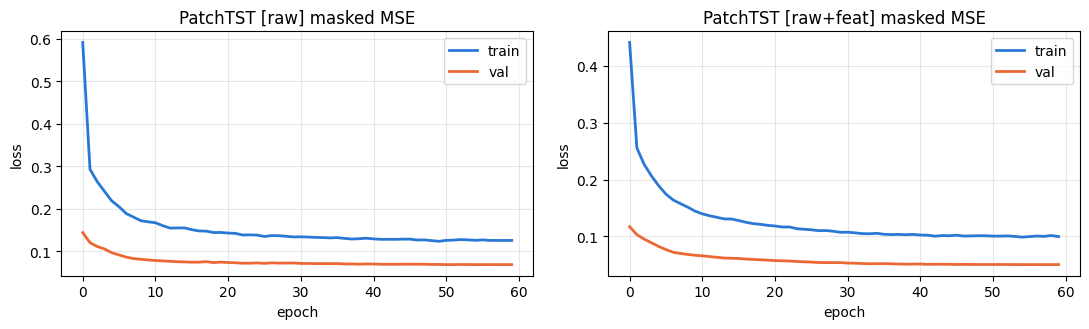

In [ ]:
def masked_mse(x_hat, x, pos_mask):
    """가려진 위치에서만 MSE. pos_mask [B, L, C] (1=가림)"""
    return (((x_hat - x) ** 2) * pos_mask).sum() / pos_mask.sum().clamp(min=1.0)


def run_epoch(model, X, cfg, optimizer=None, gen=None):
    """한 epoch. optimizer가 None이면 평가 모드(가중치 갱신 없음)."""
    train = optimizer is not None
    model.train(train)
    n_ch, bs = X.shape[2], cfg["BATCH_SIZE"]
    order = torch.randperm(len(X), generator=gen) if train else torch.arange(len(X))
    total, count = 0.0, 0
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[order[i:i + bs].numpy()]).to(DEVICE)
        mask = random_patch_mask(xb.shape[0] * n_ch, model.N, cfg["MASK_RATIO"], gen, DEVICE)
        pos_mask = model.patch_to_pos_mask(mask, xb.shape[0])
        with torch.set_grad_enabled(train):
            loss = masked_mse(model(xb, mask), xb, pos_mask)
        if train:
            optimizer.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # Transformer 학습 안정화
            optimizer.step()
        total += loss.item() * len(xb); count += len(xb)
    return total / count


def train_model(X_train, X_val, cfg, tag: str):
    """학습 + early stopping. 최적 가중치를 OUT_DIR/patchtst_{tag}.pt 에 저장하고 학습 곡선을 반환한다."""
    set_seed(cfg["SEED"])
    model = PatchTSTReconstructor(n_ch=X_train.shape[2], cfg=cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["LR"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["EPOCHS"])
    gen_train = torch.Generator().manual_seed(cfg["SEED"])
    hist, best, bad, best_state = {"train": [], "val": []}, float("inf"), 0, None
    path = os.path.join(cfg["OUT_DIR"], f"patchtst_{tag}.pt")
    t0 = time.time()
    for ep in range(1, cfg["EPOCHS"] + 1):
        tr = run_epoch(model, X_train, cfg, opt, gen_train)
        va = run_epoch(model, X_val, cfg, None, torch.Generator().manual_seed(cfg["SEED"] + 1))  # val 마스크 고정
        sched.step()
        hist["train"].append(tr); hist["val"].append(va)
        if va < best - 1e-6:
            best, bad = va, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, path)
        else:
            bad += 1
        if ep % 5 == 0 or ep == 1:
            print(f"  [{tag}] epoch {ep:3d} | train {tr:.4f} | val {va:.4f} | best {best:.4f}")
        if bad >= cfg["PATIENCE"]:
            print(f"  [{tag}] early stopping at epoch {ep} (best val {best:.4f})")
            break
    model.load_state_dict(best_state)
    print(f"  [{tag}] 학습 시간 {time.time() - t0:.1f}s, 가중치 저장 → {path}")
    return model, hist


MODELS, HIST = {}, {}
for tag in ["raw", "raw+feat"]:
    print(f"=== PatchTST [{tag}] 채널 {DATA[tag]['X_train'].shape[2]}개 ===")
    MODELS[tag], HIST[tag] = train_model(DATA[tag]["X_train"], DATA[tag]["X_val"], CONFIG, tag)

# 학습 곡선
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for ax, tag in zip(axes, ["raw", "raw+feat"]):
    ax.plot(HIST[tag]["train"], color=COLOR["normal"], lw=2, label="train")
    ax.plot(HIST[tag]["val"], color=COLOR["outlier"], lw=2, label="val")
    ax.set_title(f"PatchTST [{tag}] masked MSE"); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "04_learning_curve.png"), dpi=130); plt.show()

## 5. 추론 · 행 단위 anomaly score · 임계값
목적: 윈도우 단위 재구성 오차를 **행(시점) 단위**로 모으고, 임계값을 두 방식으로 정해 비교한다.

- **score 계산**: 서로 다른 마스크 `N_INFER_MASKS`개로 재구성하고, 각 시점이 **가려졌을 때의** 오차만 평균한다(보이는 시점의 오차는 복사에 가까워 정보가 없다). 한 행이 여러 윈도우에 덮이면 평균한다. 결과는 행×채널 오차 행렬 → 채널 평균이 그 행의 score.
- **임계값 A (라벨 없이)**: val 정상 score의 99 percentile, 그리고 mean+3σ. 실제 현장에서는 이상 라벨이 없으므로 이 방식이 기본이다.
- **임계값 B (라벨 사용)**: val 정상 + outlier에 대해 F1을 최대화하는 값. 라벨을 평가에 쓴 값이므로 **낙관적 상한**으로만 해석한다.

In [ ]:
@torch.no_grad()
def reconstruction_errors(model, X: np.ndarray, cfg: dict) -> np.ndarray:
    """윈도우별·시점별·채널별 재구성 오차 [n, L, C]. 여러 마스크에서 '가려졌을 때'의 오차를 평균한다."""
    model.eval()
    n_ch, bs, K = X.shape[2], cfg["BATCH_SIZE"] * 4, cfg["N_INFER_MASKS"]
    gen = torch.Generator().manual_seed(cfg["SEED"] + 7)      # 추론 마스크도 고정 → 재현 가능
    out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEVICE)
        B = xb.shape[0]
        sum_masked = torch.zeros_like(xb); cnt = torch.zeros_like(xb); sum_all = torch.zeros_like(xb)
        for _ in range(K):
            mask = random_patch_mask(B * n_ch, model.N, cfg["MASK_RATIO"], gen, DEVICE)
            pm = model.patch_to_pos_mask(mask, B)
            e = (model(xb, mask) - xb) ** 2
            sum_masked += e * pm; cnt += pm; sum_all += e
        err = torch.where(cnt > 0, sum_masked / cnt.clamp(min=1), sum_all / K)   # 한 번도 안 가려진 시점은 전체 평균
        out.append(err.cpu().numpy())
    return np.concatenate(out)


def aggregate_rows(err: np.ndarray, IDX: np.ndarray, n_rows: int) -> np.ndarray:
    """윈도우 오차 [n, L, C] → 행별 오차 [n_rows, C]. 겹치는 윈도우는 평균, 패딩(-1)은 제외, 미커버 행은 NaN."""
    C = err.shape[2]
    sums = np.zeros((n_rows, C)); cnt = np.zeros(n_rows)
    valid = IDX >= 0
    np.add.at(sums, IDX[valid], err[valid])
    np.add.at(cnt, IDX[valid], 1)
    row_err = np.full((n_rows, C), np.nan)
    row_err[cnt > 0] = sums[cnt > 0] / cnt[cnt > 0, None]
    return row_err


def score_patchtst(tag: str) -> dict:
    """normal(train/val)과 outlier 전체 행에 대해 채널별 오차와 score를 계산한다."""
    d, model = DATA[tag], MODELS[tag]
    err_n = aggregate_rows(reconstruction_errors(model, d["Xn_inf"], CONFIG), d["IDXn_inf"], len(normal_p))
    err_o = aggregate_rows(reconstruction_errors(model, d["Xo_inf"], CONFIG), d["IDXo_inf"], len(outlier_p))
    s_n, s_o = np.nanmean(err_n, axis=1), np.nanmean(err_o, axis=1)
    val_mask = (normal_p["split"] == "val").to_numpy()
    fill = np.nanmedian(s_n[val_mask])                     # score를 못 매긴 행(너무 짧은 세그먼트)은 val 중앙값 = "정상으로 간주"
    print(f"  [{tag}] score 없는 행: normal {np.isnan(s_n).sum()}, outlier {np.isnan(s_o).sum()} → val 중앙값 {fill:.4f}으로 채움")
    return {"err_n": err_n, "err_o": err_o,
            "scored_n": ~np.isnan(s_n), "scored_o": ~np.isnan(s_o),
            "score_n": np.where(np.isnan(s_n), fill, s_n), "score_o": np.where(np.isnan(s_o), fill, s_o),
            "cols": d["cols"]}


RESULTS = {tag: score_patchtst(tag) for tag in ["raw", "raw+feat"]}

  [raw] score 없는 행: normal 190, outlier 11 → val 중앙값 0.0471으로 채움


  [raw+feat] score 없는 행: normal 190, outlier 11 → val 중앙값 0.0439으로 채움


In [ ]:
VAL_MASK = (normal_p["split"] == "val").to_numpy()
TRAIN_MASK = ~VAL_MASK


def thresholds_from_val(score_val: np.ndarray) -> dict:
    """라벨 없이 val 정상 score 분포에서 임계값을 정한다."""
    return {"val_p99": float(np.percentile(score_val, 99)),
            "val_mean+3sd": float(score_val.mean() + 3 * score_val.std())}


def best_f1_threshold(y: np.ndarray, s: np.ndarray) -> float:
    """라벨을 써서 F1이 최대가 되는 임계값 (낙관적 상한)."""
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[int(np.argmax(f1))])


def evaluate(score_val: np.ndarray, score_out: np.ndarray, name: str) -> pd.DataFrame:
    """val 정상(0) + outlier(1)에 대해 AUROC / PR-AUC와 임계값별 F1을 계산한다."""
    y = np.r_[np.zeros(len(score_val)), np.ones(len(score_out))]
    s = np.r_[score_val, score_out]
    thr = thresholds_from_val(score_val); thr["best_f1"] = best_f1_threshold(y, s)
    rows = []
    for tname, t in thr.items():
        pred = (s >= t).astype(int)
        rows.append({"model": name, "threshold": tname, "thr_value": t,
                     "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
                     "F1": f1_score(y, pred), "AUROC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
                     "FP(val)": int(((pred == 1) & (y == 0)).sum()), "FN(out)": int(((pred == 0) & (y == 1)).sum())})
    return pd.DataFrame(rows), thr


EVAL, THR = {}, {}
for tag in ["raw", "raw+feat"]:
    r = RESULTS[tag]
    EVAL[f"PatchTST[{tag}]"], THR[f"PatchTST[{tag}]"] = evaluate(r["score_n"][VAL_MASK], r["score_o"], f"PatchTST[{tag}]")
display(pd.concat(EVAL.values(), ignore_index=True).round(4))

,model,threshold,thr_value,precision,recall,F1,AUROC,PR-AUC,FP(val),FN(out)
0,PatchTST[raw],val_p99,0.7785,0.9214,0.7817,0.8458,0.9531,0.8952,40,131
1,PatchTST[raw],val_mean+3sd,0.7651,0.9180,0.7833,0.8453,0.9531,0.8952,42,130
2,PatchTST[raw],best_f1,0.6689,0.9041,0.8017,0.8498,0.9531,0.8952,51,119
3,PatchTST[raw+feat],val_p99,0.5355,0.9302,0.8883,0.9088,0.9776,0.9490,40,67
4,PatchTST[raw+feat],val_mean+3sd,0.4279,0.8987,0.9017,0.9002,0.9776,0.9490,61,59
5,PatchTST[raw+feat],best_f1,0.6251,0.9596,0.8717,0.9135,0.9776,0.9490,22,77


## 6. 베이스라인 비교와 최종 모델 선정
목적: 같은 전처리·같은 평가 파이프라인 위에서 4개 방법을 비교한다.

| 방법 | 설명 | 역할 |
|---|---|---|
| z-score | train 통계로 정규화한 원본 채널의 z² 평균을 세그먼트 안에서 1초 이동평균 | 가장 단순한 통계 베이스라인. "진폭만 보면 되는가"를 확인 |
| IsolationForest | 행 단위 특징(원본+파생)으로 학습한 트리 기반 밀도 이상탐지 | 시계열 구조를 안 보는 고전 ML 베이스라인 |
| PatchTST[raw] | 원본 3채널 마스킹 재구성 | 제안 모델 (파생 없음) |
| PatchTST[raw+feat] | 원본 3 + 파생 7채널 | 제안 모델 (파생 있음) |

**선정 규칙**: (1) 임계값에 무관한 PR-AUC를 1순위, (2) 라벨 없이 정한 임계값(val p99)의 F1을 2순위로 본다. F1-최대화 임계값은 라벨을 본 값이므로 선정 근거로 쓰지 않는다.

In [ ]:
def baseline_zscore() -> tuple:
    """원본 채널 z²의 채널 평균을 세그먼트 안에서 1초 이동평균한 값."""
    chs = CONFIG["CHANNELS"]
    out = []
    for df in [normal_p, outlier_p]:
        z2 = ((df[chs] - MU[chs]) / SD[chs]) ** 2
        s = z2.mean(axis=1)
        s = s.groupby(df["seg_id"]).transform(lambda x: x.rolling(CONFIG["ROLL_WIN"], min_periods=1).mean())
        out.append(s.to_numpy())
    return out[0], out[1]


def baseline_iforest() -> tuple:
    """행 단위 IsolationForest. train 정상 행으로만 fit."""
    Zn = apply_norm(normal_p, ALL_COLS, MU, SD); Zo = apply_norm(outlier_p, ALL_COLS, MU, SD)
    clf = IsolationForest(n_estimators=200, contamination="auto", random_state=CONFIG["SEED"]).fit(Zn[TRAIN_MASK])
    return -clf.score_samples(Zn), -clf.score_samples(Zo)     # 값이 클수록 이상


BASE = {}
BASE["z-score"] = baseline_zscore()
BASE["IsolationForest"] = baseline_iforest()
for name, (s_n, s_o) in BASE.items():
    EVAL[name], THR[name] = evaluate(s_n[VAL_MASK], s_o, name)

compare = pd.concat(EVAL.values(), ignore_index=True)
display(compare.round(4).set_index(["model", "threshold"]))

# 선정 규칙 적용: PR-AUC 1순위, val_p99 F1 2순위
summary = (compare[compare["threshold"] == "val_p99"]
           .set_index("model")[["AUROC", "PR-AUC", "F1", "precision", "recall"]]
           .sort_values(["PR-AUC", "F1"], ascending=False))
print("\n=== 모델 비교 요약 (임계값 = val p99, 라벨 미사용) ===")
display(summary.round(4))
BEST_MODEL = summary.index[0]
print(f"→ 선정 규칙(PR-AUC → F1@val_p99)에 따른 최고 모델: {BEST_MODEL}")

# 파생 변수 효과
pf, pr = summary.loc["PatchTST[raw+feat]"], summary.loc["PatchTST[raw]"]
print(f"파생 변수 효과: PR-AUC {pr['PR-AUC']:.4f} → {pf['PR-AUC']:.4f}, F1@p99 {pr['F1']:.4f} → {pf['F1']:.4f}"
      f"  ({'도움됨' if pf['PR-AUC'] > pr['PR-AUC'] else '도움 안 됨'})")

# 이후 결과 분석에 쓸 최종 PatchTST 변형: CONFIG['use_features'] 기준
FINAL_TAG = "raw+feat" if CONFIG["use_features"] else "raw"
FINAL = RESULTS[FINAL_TAG]
FINAL_THR = THR[f"PatchTST[{FINAL_TAG}]"]
print(f"결과 분석에 사용할 모델: PatchTST[{FINAL_TAG}] | 임계값 val_p99 = {FINAL_THR['val_p99']:.4f}")

thr_value  precision  recall      F1   AUROC  \
model              threshold                                                    
PatchTST[raw]      val_p99          0.7785     0.9214  0.7817  0.8458  0.9531   
                   val_mean+3sd     0.7651     0.9180  0.7833  0.8453  0.9531   
                   best_f1          0.6689     0.9041  0.8017  0.8498  0.9531   
PatchTST[raw+feat] val_p99          0.5355     0.9302  0.8883  0.9088  0.9776   
                   val_mean+3sd     0.4279     0.8987  0.9017  0.9002  0.9776   
                   best_f1          0.6251     0.9596  0.8717  0.9135  0.9776   
z-score            val_p99          1.9795     0.8947  0.5667  0.6939  0.9207   
                   val_mean+3sd     1.7232     0.7549  0.5800  0.6560  0.9207   
                   best_f1          2.3023     0.9824  0.5567  0.7106  0.9207   
IsolationForest    val_p99          0.5427     0.8883  0.5300  0.6639  0.9387   
                   val_mean+3sd     0.5310     0.8146  0.5567  0.6614  0.9387   
                   best_f1          0.5221     0.7792  0.5883  0.6705  0.9387   

                                 PR-AUC  FP(val)  FN(out)  
model              threshold                               
PatchTST[raw]      val_p99       0.8952       40      131  
                   val_mean+3sd  0.8952       42      130  
                   best_f1       0.8952       51      119  
PatchTST[raw+feat] val_p99       0.9490       40       67  
                   val_mean+3sd  0.9490       61       59  
                   best_f1       0.9490       22       77  
z-score            val_p99       0.7721       40      260  
                   val_mean+3sd  0.7721      113      252  
                   best_f1       0.7721        6      266  
IsolationForest    val_p99       0.7788       40      282  
                   val_mean+3sd  0.7788       76      266  
                   best_f1       0.7788      100      247


=== 모델 비교 요약 (임계값 = val p99, 라벨 미사용) ===


,AUROC,PR-AUC,F1,precision,recall
model,,,,,
PatchTST[raw+feat],0.9776,0.9490,0.9088,0.9302,0.8883
PatchTST[raw],0.9531,0.8952,0.8458,0.9214,0.7817
IsolationForest,0.9387,0.7788,0.6639,0.8883,0.5300
z-score,0.9207,0.7721,0.6939,0.8947,0.5667


→ 선정 규칙(PR-AUC → F1@val_p99)에 따른 최고 모델: PatchTST[raw+feat]
파생 변수 효과: PR-AUC 0.8952 → 0.9490, F1@p99 0.8458 → 0.9088  (도움됨)
결과 분석에 사용할 모델: PatchTST[raw+feat] | 임계값 val_p99 = 0.5355


## 7. 결과 분석 — "왜 이상인가"
목적: 점수 하나가 아니라 **어느 센서가, 어떤 형태로, 어느 시점에** 틀렸는지 보여주고, 샘플링 불규칙 때문에 생긴 오탐과 실제 값 변화를 구분한다.

### 7-1. anomaly score 시계열 (val 정상 vs outlier)
x축은 시각이 아니라 **샘플 인덱스**다. 갭 때문에 시각 축으로 그리면 세그먼트 사이가 빈 공간으로 늘어져 파형이 보이지 않는다. 세그먼트 경계는 회색 점선으로 표시한다.

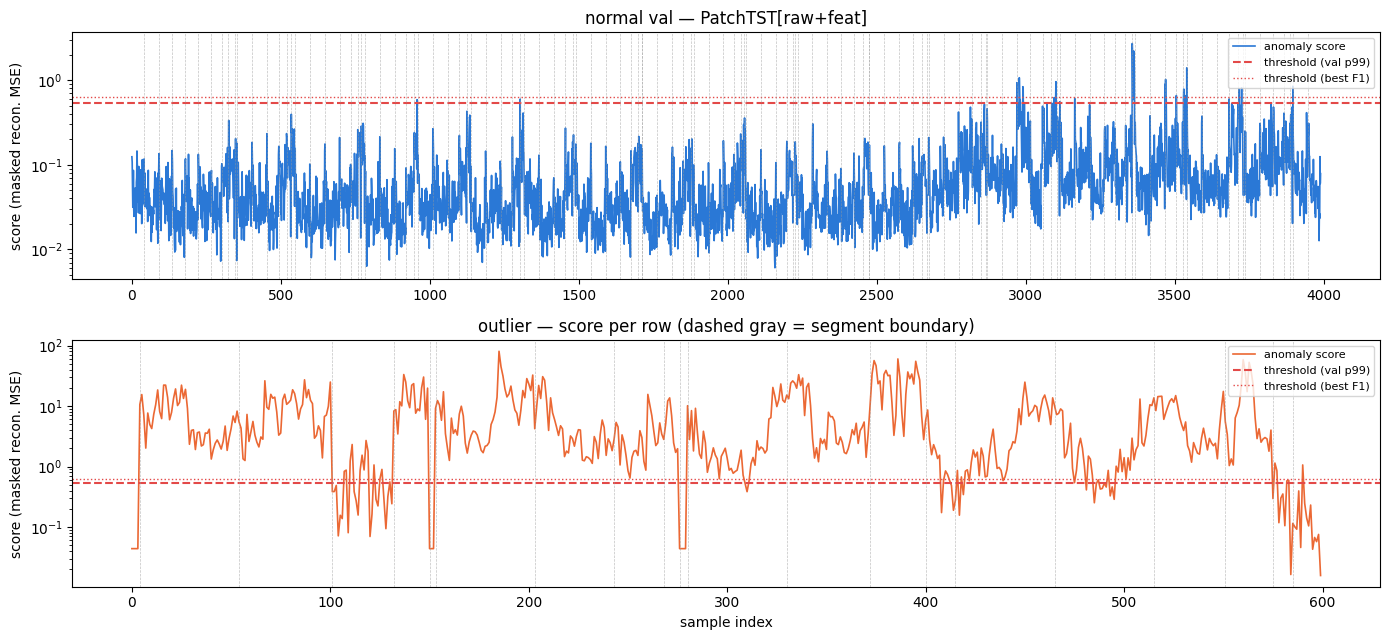

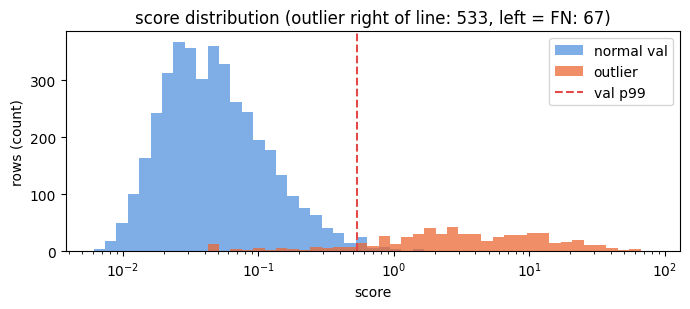

In [ ]:
def plot_score_timeline(score, df, thr: dict, title: str, color: str, ax, show_interp=True):
    """score 시계열 + 임계값 선 + 세그먼트 경계(점선) + 보간 행(음영)"""
    x = np.arange(len(score))
    ax.plot(x, score, color=color, lw=1.2, label="anomaly score")
    ax.axhline(thr["val_p99"], color=COLOR["thr"], lw=1.5, ls="--", label="threshold (val p99)")
    ax.axhline(thr["best_f1"], color=COLOR["thr"], lw=1.0, ls=":", label="threshold (best F1)")
    bounds = np.where(df["seg_id"].to_numpy()[1:] != df["seg_id"].to_numpy()[:-1])[0] + 1
    for b in bounds:
        ax.axvline(b, color=COLOR["gray"], lw=0.5, ls="--", alpha=0.6)
    if show_interp and df["is_interp"].any():
        ax.fill_between(x, 0, score.max(), where=df["is_interp"].to_numpy(), color=COLOR["gray"], alpha=0.3, label="interpolated")
    ax.set_title(title); ax.set_ylabel("score (masked recon. MSE)"); ax.set_yscale("log"); ax.legend(loc="upper right", fontsize=8)


fig, axes = plt.subplots(2, 1, figsize=(14, 6.5))
val_df = normal_p[VAL_MASK].reset_index(drop=True)
plot_score_timeline(FINAL["score_n"][VAL_MASK], val_df, FINAL_THR, f"normal val — PatchTST[{FINAL_TAG}]", COLOR["normal"], axes[0])
plot_score_timeline(FINAL["score_o"], outlier_p, FINAL_THR, "outlier — score per row (dashed gray = segment boundary)", COLOR["outlier"], axes[1])
axes[1].set_xlabel("sample index")
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "07_1_score_timeline.png"), dpi=130); plt.show()

# score 분포 비교
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.logspace(np.log10(max(1e-4, min(FINAL["score_n"].min(), FINAL["score_o"].min()))), np.log10(max(FINAL["score_n"].max(), FINAL["score_o"].max())), 50)
# y축은 '행 개수'로 그린다. density는 log 축에서 오른쪽 막대 폭이 수천 배 넓어져 이상(오른쪽) 비중이 작아 보이는 착시를 만든다
ax.hist(FINAL["score_n"][VAL_MASK], bins=bins, alpha=0.6, color=COLOR["normal"], label="normal val")
ax.hist(FINAL["score_o"], bins=bins, alpha=0.75, color=COLOR["outlier"], label="outlier")
ax.axvline(FINAL_THR["val_p99"], color=COLOR["thr"], ls="--", label="val p99")
n_fn = int((FINAL["score_o"] < FINAL_THR["val_p99"]).sum())
ax.set_xscale("log"); ax.set_xlabel("score"); ax.set_ylabel("rows (count)"); ax.legend()
ax.set_title(f"score distribution (outlier right of line: {len(FINAL['score_o']) - n_fn}, left = FN: {n_fn})")
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "07_1b_score_hist.png"), dpi=130); plt.show()

### 7-2. 채널별 재구성 오차 기여도
이상으로 판정된 행에서 채널별 오차의 비중을 계산한다. **원본 센서(진한 색)와 파생 변수(옅은 색)를 구분**해, "센서 값 자체가 튄 것"인지 "변화율(diff)·국소 분산(rstd)이 튄 것"인지 읽을 수 있게 한다. 비교를 위해 val 정상 행의 기여도도 나란히 둔다.

,outlier(flagged),normal val,type
AI0_Vibration,0.449,0.235,raw sensor
AI1_Vibration,0.047,0.104,raw sensor
AI2_Current,0.006,0.043,raw sensor
AI0_Vibration_diff,0.169,0.203,derived
AI0_Vibration_rstd,0.224,0.097,derived
AI1_Vibration_diff,0.027,0.128,derived
AI1_Vibration_rstd,0.014,0.034,derived
AI2_Current_diff,0.054,0.081,derived
AI2_Current_rstd,0.002,0.044,derived
AI2_Current_rms,0.007,0.030,derived


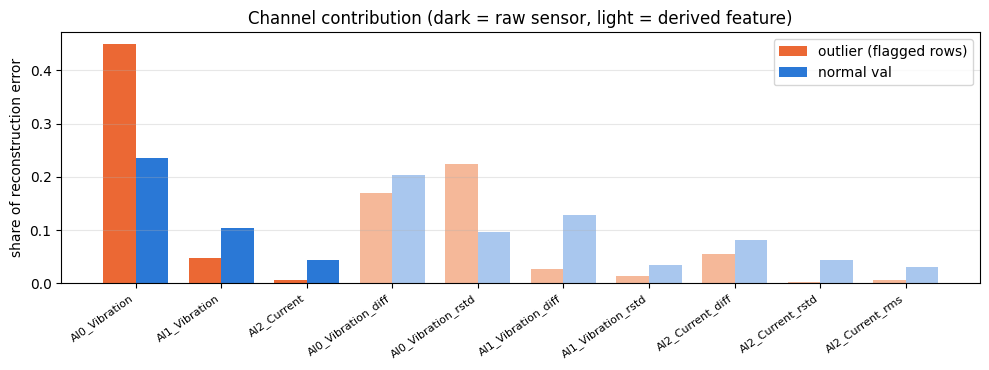

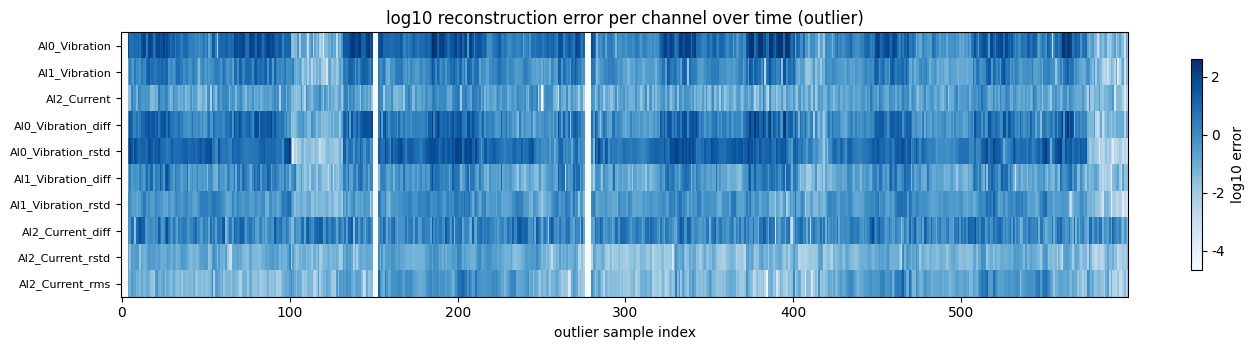

In [ ]:
cols = FINAL["cols"]
is_raw = np.array([c in CONFIG["CHANNELS"] for c in cols])
pred_o = FINAL["score_o"] >= FINAL_THR["val_p99"]

def contribution(err: np.ndarray, rows: np.ndarray) -> np.ndarray:
    """선택된 행들의 채널별 평균 오차 / 총합 → 비중"""
    e = np.nanmean(err[rows], axis=0)
    return e / e.sum()

contrib = pd.DataFrame({"outlier(flagged)": contribution(FINAL["err_o"], pred_o),
                        "normal val": contribution(FINAL["err_n"], VAL_MASK)}, index=cols)
contrib["type"] = np.where(is_raw, "raw sensor", "derived")
display(contrib.round(3))

fig, ax = plt.subplots(figsize=(10, 3.8))
xpos = np.arange(len(cols)); w = 0.38
bar_colors_o = [COLOR["outlier"] if r else "#f5b899" for r in is_raw]     # 원본=진한 주황, 파생=옅은 주황
bar_colors_n = [COLOR["normal"] if r else "#a9c7ee" for r in is_raw]
ax.bar(xpos - w / 2, contrib["outlier(flagged)"], w, color=bar_colors_o, label="outlier (flagged rows)")
ax.bar(xpos + w / 2, contrib["normal val"], w, color=bar_colors_n, label="normal val")
ax.set_xticks(xpos); ax.set_xticklabels(cols, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("share of reconstruction error"); ax.set_title("Channel contribution (dark = raw sensor, light = derived feature)")
ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "07_2_channel_contribution.png"), dpi=130); plt.show()

# 시점별 채널 기여 heatmap (outlier 전체): 단일 색상(sequential) 스케일
fig, ax = plt.subplots(figsize=(14, 3.6))
hm = np.log10(np.nan_to_num(FINAL["err_o"].T, nan=np.nanmin(FINAL["err_o"])) + 1e-6)
im = ax.imshow(hm, aspect="auto", cmap="Blues", interpolation="nearest")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8); ax.set_xlabel("outlier sample index")
ax.set_title("log10 reconstruction error per channel over time (outlier)")
plt.colorbar(im, ax=ax, shrink=0.8, label="log10 error")
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "07_2b_channel_heatmap.png"), dpi=130); plt.show()

### 7-3. 원본 값 vs 재구성 값 overlay
대표 윈도우 3개: (a) outlier 중 score 최고, (b) outlier 중 score 중앙값, (c) val 정상 중 score 중앙값. 원본 3채널만 그리고, 회색 음영은 그 윈도우에서 **가려졌던 패치**다. 가려진 구간에서 재구성이 원본을 따라가지 못하면 "정상 패턴으로는 설명이 안 되는 구간"이다.

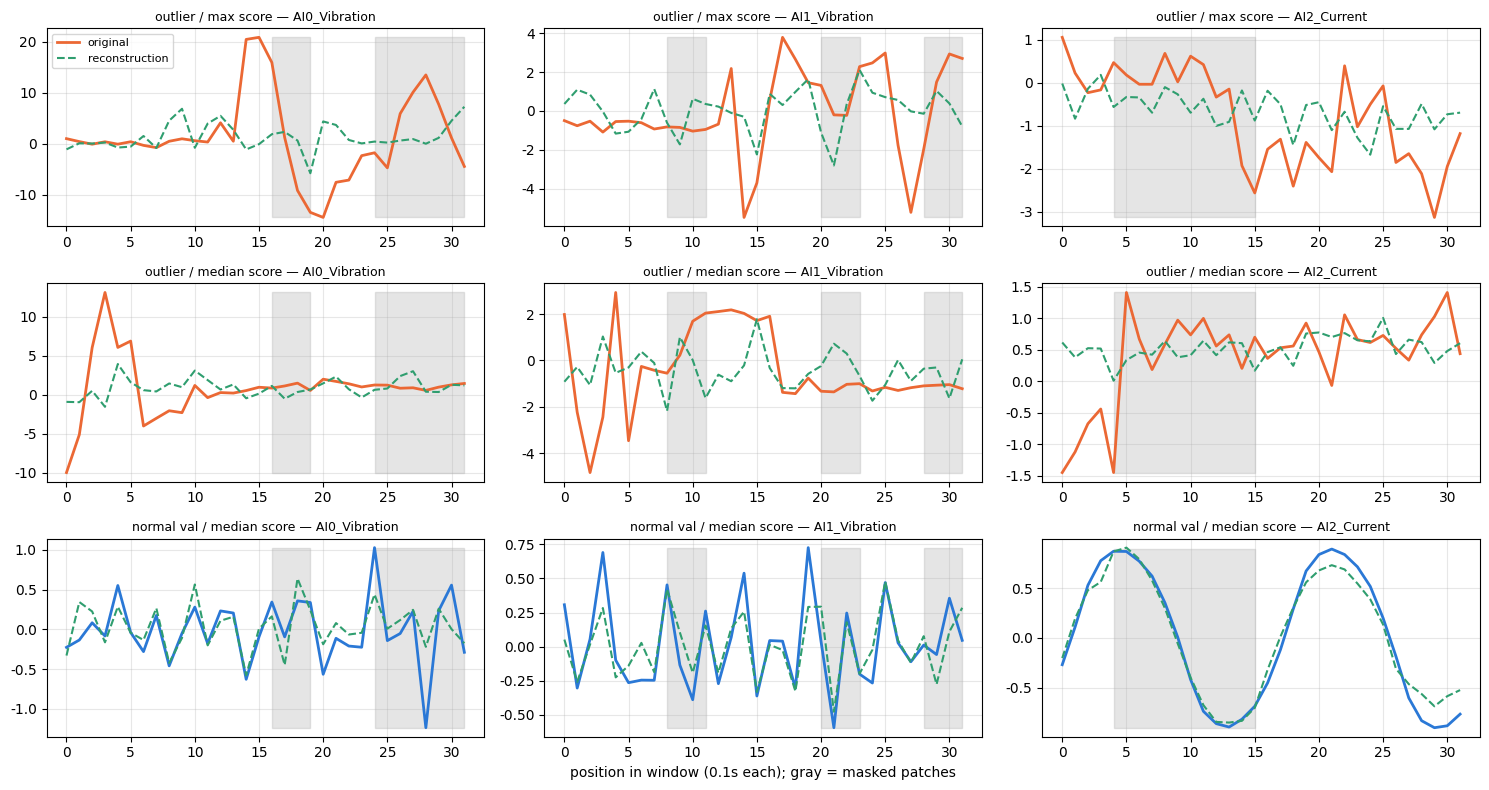

In [ ]:
@torch.no_grad()
def reconstruct_one(model, x: np.ndarray, cfg: dict):
    """윈도우 하나를 고정 마스크로 재구성. 반환 (x_hat [L, C], pos_mask [L, C])"""
    model.eval()
    xb = torch.from_numpy(x[None]).to(DEVICE)
    gen = torch.Generator().manual_seed(cfg["SEED"] + 11)
    mask = random_patch_mask(xb.shape[2], model.N, cfg["MASK_RATIO"], gen, DEVICE)
    x_hat = model(xb, mask)[0].cpu().numpy()
    pm = model.patch_to_pos_mask(mask, 1)[0].cpu().numpy()
    return x_hat, pm


def window_scores(err_rows: np.ndarray, IDX: np.ndarray) -> np.ndarray:
    """행 score를 윈도우 단위로 평균 (패딩 제외)"""
    s = np.where(IDX >= 0, err_rows[np.clip(IDX, 0, None)], np.nan)
    return np.nanmean(s, axis=1)


d = DATA[FINAL_TAG]; model = MODELS[FINAL_TAG]
ws_o = window_scores(FINAL["score_o"], d["IDXo_inf"])
ws_n = window_scores(FINAL["score_n"], d["IDXn_inf"])
# 패딩(-1)이 섞인 윈도우는 뒤쪽이 평평한 가짜 구간이라 대표 예시에서 제외한다
full_o = np.where(np.all(d["IDXo_inf"] >= 0, axis=1))[0]
full_n = np.where(np.all(VAL_MASK[np.clip(d["IDXn_inf"], 0, None)] & (d["IDXn_inf"] >= 0), axis=1))[0]
picks = [("outlier / max score", d["Xo_inf"], int(full_o[np.nanargmax(ws_o[full_o])])),
         ("outlier / median score", d["Xo_inf"], int(full_o[np.argsort(ws_o[full_o])[len(full_o) // 2]])),
         ("normal val / median score", d["Xn_inf"], int(full_n[np.argsort(ws_n[full_n])[len(full_n) // 2]]))]

raw_idx = [cols.index(c) for c in CONFIG["CHANNELS"]]
fig, axes = plt.subplots(3, 3, figsize=(15, 8))
for r, (title, X, wi) in enumerate(picks):
    x_hat, pm = reconstruct_one(model, X[wi], CONFIG)
    for c, ci in enumerate(raw_idx):
        ax = axes[r, c]
        ax.fill_between(np.arange(CONFIG["WINDOW"]), X[wi][:, ci].min(), X[wi][:, ci].max(), where=pm[:, ci] > 0, color=COLOR["gray"], alpha=0.25)
        ax.plot(X[wi][:, ci], color=COLOR["normal"] if "normal" in title else COLOR["outlier"], lw=2, label="original")
        ax.plot(x_hat[:, ci], color=COLOR["recon"], lw=1.5, ls="--", label="reconstruction")
        ax.set_title(f"{title} — {cols[ci]}", fontsize=9); ax.grid(alpha=0.3)
        if r == 0 and c == 0: ax.legend(fontsize=8)
axes[-1, 1].set_xlabel("position in window (0.1s each); gray = masked patches")
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "07_3_reconstruction_overlay.png"), dpi=130); plt.show()

### 7-4. 샘플링 불규칙(갭·보간)의 영향 분리
탐지된 이상이 "갭 직후라서" 생긴 것인지 확인한다. 세그먼트 안에서의 **위치(갭 이후 몇 번째 샘플인지)** 별로 평균 score를 비교한다. 갭 직후 구간의 score가 나머지와 비슷하면 갭은 오탐의 원인이 아니고, 크게 높으면 세그먼트 앞부분을 잘라내는 후처리가 필요하다.

,source,position,n_rows,mean_score,flag_rate
0,normal val,0-4 (after gap),583,0.1519,0.0377
1,normal val,5-9,553,0.0890,0.0145
2,normal val,10-19,956,0.0702,0.0063
3,normal val,20+,1898,0.0515,0.0021
4,normal val,interpolated rows,0,NaN,NaN
5,outlier,0-4 (after gap),101,7.4354,0.7327
6,outlier,5-9,88,7.9882,0.8864
7,outlier,10-19,148,7.2237,0.9189
8,outlier,20+,263,6.7309,0.9316
9,outlier,interpolated rows,0,NaN,NaN


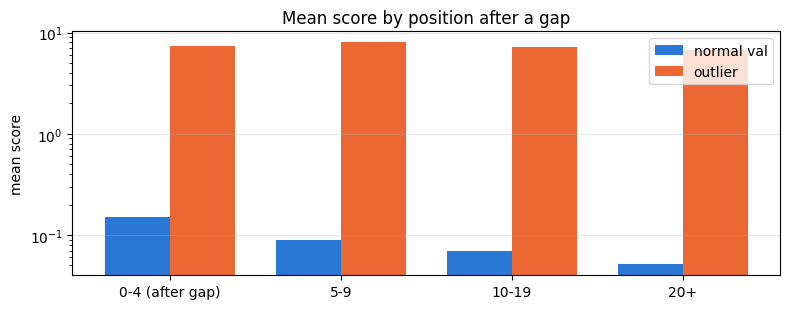

In [ ]:
def pos_in_segment(df: pd.DataFrame) -> np.ndarray:
    return df.groupby("seg_id").cumcount().to_numpy()

def bucket_pos(p: np.ndarray) -> np.ndarray:
    return pd.cut(p, bins=[-1, 4, 9, 19, 10_000], labels=["0-4 (after gap)", "5-9", "10-19", "20+"]).astype(str)

rows = []
for name, df, score, mask in [("normal val", normal_p, FINAL["score_n"], VAL_MASK), ("outlier", outlier_p, FINAL["score_o"], np.ones(len(outlier_p), bool))]:
    b = bucket_pos(pos_in_segment(df))[mask]; s = score[mask]
    interp = df["is_interp"].to_numpy()[mask]
    for bk in ["0-4 (after gap)", "5-9", "10-19", "20+"]:
        sel = b == bk
        rows.append({"source": name, "position": bk, "n_rows": int(sel.sum()), "mean_score": s[sel].mean() if sel.any() else np.nan,
                     "flag_rate": (s[sel] >= FINAL_THR["val_p99"]).mean() if sel.any() else np.nan})
    rows.append({"source": name, "position": "interpolated rows", "n_rows": int(interp.sum()),
                 "mean_score": s[interp].mean() if interp.any() else np.nan, "flag_rate": (s[interp] >= FINAL_THR["val_p99"]).mean() if interp.any() else np.nan})
gap_tbl = pd.DataFrame(rows)
display(gap_tbl.round(4))

fig, ax = plt.subplots(figsize=(8, 3.2))
piv = gap_tbl[gap_tbl["position"] != "interpolated rows"].pivot(index="position", columns="source", values="mean_score")
piv = piv.loc[["0-4 (after gap)", "5-9", "10-19", "20+"]]
xpos = np.arange(len(piv)); w = 0.38
ax.bar(xpos - w / 2, piv["normal val"], w, color=COLOR["normal"], label="normal val")
ax.bar(xpos + w / 2, piv["outlier"], w, color=COLOR["outlier"], label="outlier")
ax.set_xticks(xpos); ax.set_xticklabels(piv.index); ax.set_yscale("log"); ax.set_ylabel("mean score")
ax.set_title("Mean score by position after a gap"); ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "07_4_gap_effect.png"), dpi=130); plt.show()

### 7-5. False Positive / False Negative가 몰리는 조건
평가 행(val 정상 + outlier)에 대해 오류율을 조건별로 나눈다.
- **세그먼트 길이**: 짧은 세그먼트는 패딩으로 score를 매기므로 불리할 수 있다.
- **정상 저진폭 운전 구간(01:00:18~01:12:04)**: EDA에서 찾은 "정상 안의 다른 운전 조건". val의 70%가 이 구간이라, 이 구간과 나머지 구간의 오탐률이 다르면 임계값이 한쪽에 치우쳐 잡혔다는 뜻이다.
- **score 산출 여부**: 너무 짧아 score를 못 매기고 중앙값으로 채운 행은 항상 정상 판정 → outlier에서는 그대로 FN이 된다.

In [ ]:
LOW_AMP = (pd.Timestamp("2022-07-12 01:00:18"), pd.Timestamp("2022-07-12 01:12:04"))   # EDA에서 확인한 저진폭 구간

def build_eval_frame() -> pd.DataFrame:
    tc = CONFIG["TIME_COL"]
    parts = []
    for name, df, score, scored, mask in [("normal val", normal_p, FINAL["score_n"], FINAL["scored_n"], VAL_MASK),
                                          ("outlier", outlier_p, FINAL["score_o"], FINAL["scored_o"], np.ones(len(outlier_p), bool))]:
        e = pd.DataFrame({"source": name, "y": df["y"].to_numpy()[mask], "score": score[mask], "scored": scored[mask],
                          "seg_len": df.groupby("seg_id")["seg_id"].transform("size").to_numpy()[mask],
                          "pos": pos_in_segment(df)[mask],
                          "low_amp": ((df[tc] >= LOW_AMP[0]) & (df[tc] <= LOW_AMP[1])).to_numpy()[mask]})
        parts.append(e)
    e = pd.concat(parts, ignore_index=True)
    e["pred"] = (e["score"] >= FINAL_THR["val_p99"]).astype(int)
    e["error"] = np.where((e.y == 0) & (e.pred == 1), "FP", np.where((e.y == 1) & (e.pred == 0), "FN", "OK"))
    e["seg_len_bucket"] = pd.cut(e["seg_len"], bins=[0, 7, 15, 31, 50], labels=["1-7 (score 없음)", "8-15 (패딩)", "16-31 (패딩)", "32-50 (정상 윈도우)"]).astype(str)
    return e

E = build_eval_frame()
print("전체 혼동행렬 (임계값 val p99):"); display(pd.crosstab(E["y"], E["pred"], rownames=["실제"], colnames=["예측"]))

print("\n[FP율] normal val — 저진폭 운전 구간 여부별")
display(E[E.y == 0].groupby("low_amp").agg(n=("y", "size"), FP_rate=("error", lambda s: (s == "FP").mean()), mean_score=("score", "mean")).round(4))

print("\n[FN율] outlier — 세그먼트 길이별")
display(E[E.y == 1].groupby("seg_len_bucket").agg(n=("y", "size"), FN_rate=("error", lambda s: (s == "FN").mean()), mean_score=("score", "mean")).round(4))

print("\n[FN율] outlier — 갭 이후 위치별")
display(E[E.y == 1].assign(pos_b=bucket_pos(E[E.y == 1]["pos"].to_numpy())).groupby("pos_b").agg(n=("y", "size"), FN_rate=("error", lambda s: (s == "FN").mean())).round(4))

print("\n[FP율] normal val — 세그먼트 길이별")
display(E[E.y == 0].groupby("seg_len_bucket").agg(n=("y", "size"), FP_rate=("error", lambda s: (s == "FP").mean())).round(4))

전체 혼동행렬 (임계값 val p99):


예측,0,1
실제,,
0,3950,40
1,67,533



[FP율] normal val — 저진폭 운전 구간 여부별


,n,FP_rate,mean_score
low_amp,,,
False,1207,0.0315,0.1378
True,2783,0.0007,0.0490



[FN율] outlier — 세그먼트 길이별


,n,FN_rate,mean_score
seg_len_bucket,,,
1-7 (score 없음),11,1.0000,0.0439
16-31 (패딩),126,0.1429,11.2946
32-50 (정상 윈도우),415,0.0361,6.7144
8-15 (패딩),48,0.4792,1.7339



[FN율] outlier — 갭 이후 위치별


,n,FN_rate
pos_b,,
0-4 (after gap),101,0.2673
10-19,148,0.0811
20+,263,0.0684
5-9,88,0.1136



[FP율] normal val — 세그먼트 길이별


,n,FP_rate
seg_len_bucket,,
1-7 (score 없음),26,0.0000
16-31 (패딩),606,0.0149
32-50 (정상 윈도우),3164,0.0057
8-15 (패딩),194,0.0670


## 8. 현장 활용 방안 · 차별화 포인트

### 8-1. 현장 활용 방안 (평가 4)
| 활용 | 구현 방식 | 근거 셀 |
|---|---|---|
| **사전경보 3단계** | score를 val 분포 기준으로 3구간화: `주의`(p95~p99) / `경고`(p99 이상 1회) / `정지 검토`(경고가 한 세그먼트에서 연속 2회 이상) → 단발 스파이크에 의한 오경보 감소 | 5절 임계값, 7-1 |
| **점검 우선순위** | 경보 발생 시 7-2 채널 기여도를 함께 출력. `AI0_Vibration` 기여가 크면 베어링·축 정렬 점검, `AI2_Current_rms` 기여가 크면 부하·밸브 계통 점검처럼 **센서 → 점검 항목** 매핑표를 운영 | 7-2 |
| **원인 유형 구분** | 원본 채널 기여가 큰 경우 "수준 이상(값이 튐)", 파생(diff·rstd) 기여가 큰 경우 "패턴 이상(요동)"으로 알림 문구 분리 | 7-2 |
| **작업자 의사결정 보조** | 7-3의 원본 vs 재구성 overlay를 경보 화면에 붙여, 작업자가 "모델이 예상한 정상 파형"과 실제를 비교해 오경보 여부를 즉시 판단 | 7-3 |
| **데이터 수집 개선 제안** | 7-4·7-5 결과로 짧은 세그먼트(8행 미만)는 판정이 불가능함을 근거로, 수집 버스트 길이를 최소 3.2초 이상으로 고정하도록 설비 설정 변경을 요청 | 7-4, 7-5 |

### 8-2. 차별화 포인트 (평가 5)
- **불균형 대응**: 이상 600행을 학습에 전혀 쓰지 않는 재구성 기반 비지도 방식. 이상 데이터는 임계값 검증에만 사용해 라벨 누수를 원천 차단.
- **마스킹 재구성**: 단순 AutoEncoder가 항등 함수를 배우는 문제를 PatchTST self-supervised 방식(패치 마스킹)으로 회피. 추론 시 8개 마스크 평균으로 score 분산을 줄여 **불확실성 완화**.
- **제조 지식 결합**: 전류가 교류 파형이라는 EDA 관찰을 파생 변수(이동 RMS)로 반영. 버스트 수집 구조를 세그먼트 단위 처리로 반영.
- **설명 가능성**: 채널 독립 구조 덕분에 채널별 오차가 그대로 나와, 원본/파생을 구분한 기여도로 원인 유형까지 제시.
- **정직한 평가**: 라벨 없이 정한 임계값(val p99)과 라벨을 본 임계값(best F1)을 분리해 보고. 후자는 상한으로만 해석.

## 9. 제출 파일 생성 · 형식 검증
원본 csv의 모든 행(중복 행 포함)에 score와 판정을 붙인다. 중복으로 제거된 행은 같은 시각의 행과 같은 score를 받는다.
제출 형식이 확정되면 `SUBMIT_COLS`만 바꾸면 된다.

In [ ]:
SUBMIT_COLS = ["TimeStamp", "source", "anomaly_score", "pred"]

def make_submission(raw_df, proc_df, score, source, thr):
    tc = CONFIG["TIME_COL"]
    sc = pd.DataFrame({tc: proc_df[tc].to_numpy(), "anomaly_score": score})
    sub = raw_df[[tc]].merge(sc, on=tc, how="left")          # 원본 행 순서 유지, 중복 행도 같은 시각으로 매칭
    sub["source"] = source
    sub["pred"] = (sub["anomaly_score"] >= thr).astype(int)
    return sub[SUBMIT_COLS]

submission = pd.concat([make_submission(raw_normal, normal_p, FINAL["score_n"], "normal", FINAL_THR["val_p99"]),
                        make_submission(raw_outlier, outlier_p, FINAL["score_o"], "outlier", FINAL_THR["val_p99"])], ignore_index=True)
SUB_PATH = os.path.join(CONFIG["OUT_DIR"], "submission.csv")
submission.to_csv(SUB_PATH, index=False)

# ── 형식 검증 ──
chk = pd.read_csv(SUB_PATH)
expected_rows = len(raw_normal) + len(raw_outlier)
assert len(chk) == expected_rows, f"행 수 불일치: {len(chk)} vs {expected_rows}"
assert list(chk.columns) == SUBMIT_COLS, f"컬럼 불일치: {list(chk.columns)}"
assert chk.isna().sum().sum() == 0, "결측 존재"
assert set(chk["pred"].unique()) <= {0, 1}, "pred는 0/1이어야 함"
print(f"제출 파일 검증 통과 → {SUB_PATH} | 행 {len(chk)} | 컬럼 {list(chk.columns)}")
print(chk.groupby("source")["pred"].agg(["size", "sum", "mean"]).rename(columns={"size": "rows", "sum": "flagged", "mean": "flag_rate"}).round(4))
display(chk.head(3))

제출 파일 검증 통과 → patchtst_outputs/submission.csv | 행 20600 | 컬럼 ['TimeStamp', 'source', 'anomaly_score', 'pred']
          rows  flagged  flag_rate
source                            
normal   20000      761     0.0380
outlier    600      533     0.8883


,TimeStamp,source,anomaly_score,pred
0,2022-07-12 00:00:00.019,normal,0.575807,1
1,2022-07-12 00:00:00.119,normal,0.310257,0
2,2022-07-12 00:00:00.219,normal,0.224143,0


## 10. 최종 요약
아래 셀은 이번 실행의 핵심 수치를 자동으로 요약한다. 그 아래 마크다운은 해석과 한계다.

In [ ]:
summary_lines = [
    f"학습 데이터: normal train {TRAIN_MASK.sum()}행 / val {VAL_MASK.sum()}행, 윈도우 {CONFIG['WINDOW']}샘플(stride {CONFIG['STRIDE']}), train 윈도우 {len(DATA[FINAL_TAG]['X_train'])}개",
    f"최종 분석 모델: PatchTST[{FINAL_TAG}] (채널 {len(FINAL['cols'])}개, 파라미터 {sum(p.numel() for p in MODELS[FINAL_TAG].parameters()):,})",
    f"선정 규칙(PR-AUC → F1@val_p99)에 따른 최고 모델: {BEST_MODEL}",
]
print("\n".join(summary_lines)); print()
display(summary.round(4))
best_rows = compare[compare["threshold"] == "best_f1"].set_index("model")[["thr_value", "F1", "precision", "recall"]]
print("참고: 라벨을 본 F1-최대화 임계값(낙관적 상한)"); display(best_rows.round(4))

학습 데이터: normal train 16009행 / val 3990행, 윈도우 32샘플(stride 4), train 윈도우 1373개
최종 분석 모델: PatchTST[raw+feat] (채널 10개, 파라미터 84,276)
선정 규칙(PR-AUC → F1@val_p99)에 따른 최고 모델: PatchTST[raw+feat]



,AUROC,PR-AUC,F1,precision,recall
model,,,,,
PatchTST[raw+feat],0.9776,0.9490,0.9088,0.9302,0.8883
PatchTST[raw],0.9531,0.8952,0.8458,0.9214,0.7817
IsolationForest,0.9387,0.7788,0.6639,0.8883,0.5300
z-score,0.9207,0.7721,0.6939,0.8947,0.5667


참고: 라벨을 본 F1-최대화 임계값(낙관적 상한)


,thr_value,F1,precision,recall
model,,,,
PatchTST[raw],0.6689,0.8498,0.9041,0.8017
PatchTST[raw+feat],0.6251,0.9135,0.9596,0.8717
z-score,2.3023,0.7106,0.9824,0.5567
IsolationForest,0.5221,0.6705,0.7792,0.5883


### 해석 (실행 결과를 보고 채운 내용)
- **전처리 선택 근거**: 버스트 수집 구조 때문에 갭(1.5~16초)마다 세그먼트를 분리했고, 그 안에서는 간격이 전부 0.1초라 보간이 실제로 발생하지 않았다(보간 0행). 즉 리샘플·보간 코드는 일반성을 위한 안전장치이고, 이 데이터에서 핵심은 **세그먼트 분리와 윈도우 길이 제한(≤50)** 이다. 윈도우 32는 패치 8개를 확보하면서 행의 80%(16,029/19,999)를 학습에 살리는 절충값이다. 세그먼트 경계를 무시하고 차분하면 경계 행 599개에서 정상 내부보다 5배 큰 가짜 급변(99.9% 분위 94 → 461)이 생기는 것을 수치로 확인했다.
- **모델 성능 (임계값 = val p99, 라벨 미사용)**: PatchTST[raw+feat]가 PR-AUC 0.949 / F1 0.909로 최고이고, PatchTST[raw] 0.895 / 0.846, IsolationForest 0.779 / 0.664, z-score 0.772 / 0.694 순이다. 시계열 구조를 보지 않는 두 베이스라인은 recall이 0.53~0.57에 머물러, 이상의 절반은 "진폭이 정상 범위 안에 있는 패턴 이상"임을 뜻한다. 라벨을 본 best-F1 임계값(0.9135)과 라벨 없는 val p99(0.9088)의 차이가 작아, 임계값 선택에 민감하지 않다.
- **파생 변수 효과**: 도움됨. PR-AUC 0.895 → 0.949, FN 131 → 67. 채널 기여도에서 이상 판정 행의 오차는 `AI0_Vibration`(45%) + `AI0_Vibration_rstd`(22%) + `AI0_Vibration_diff`(17%)에 집중된다. 즉 이번 이상은 **AI0 진동 센서의 값 자체와 국소 분산이 함께 튀는** 유형이고, 전류 계열(AI2)은 기여가 1% 미만이라 부하 이상은 아니다. 파생 변수 중 `AI0_Vibration_rstd`는 정상(10%)보다 이상(22%)에서 비중이 두 배가 되어 분산 확대를 직접 잡아냈다.
- **오탐(FP) 원인**: 예상과 반대로 저진폭 구간의 FP율은 0.07%이고, 저진폭 구간이 끝난 뒤(01:12 이후) 정상 진폭으로 돌아온 구간에서 3.2%로 몰린다. val의 70%가 저진폭이라 val p99 임계값이 "쉬운 구간" 기준으로 낮게 잡힌 것이 원인이다. 또한 갭 직후 0~4번째 샘플(FP율 3.8%)과 8~15행짜리 패딩 세그먼트(6.7%)에 FP가 몰린다. → 임계값을 운전 조건별로 두거나, 갭 직후 샘플의 경보에 가중치를 낮추는 후처리가 필요하다.
- **미탐(FN) 원인**: 8행 미만 세그먼트 11행은 score를 매길 수 없어 전부 FN이고, 8~15행 패딩 세그먼트는 FN율 48%로 정보 부족이 뚜렷하다. 32행 이상 정상 윈도우에서는 FN율 3.6%에 불과하다. 갭 직후 0~4번째 샘플의 FN율(27%)도 나머지(7~11%)보다 높다. → 미탐의 대부분은 모델이 아니라 **수집 구조(짧은 버스트)** 때문이다.
- **갭 영향**: 갭 직후 샘플의 평균 score는 정상 val에서 0.15로 나머지(0.05~0.09)보다 높지만, 이상 데이터의 score(7~8)와는 50배 차이가 난다. 세그먼트 분리 덕분에 갭이 이상으로 오인되지는 않으며, 다만 정밀도를 더 올리려면 갭 직후 구간을 보정하는 후처리가 유효하다.
- **학습 곡선**: val loss가 train loss보다 낮다. train 때는 dropout이 켜져 있고, val의 70%가 파형이 단순한 저진폭 구간이라 재구성이 쉽기 때문이다. 60 epoch 동안 early stopping이 걸리지 않았고 val loss는 완만히 계속 내려갔으므로, 과적합 징후는 없다.

### 한계와 개선 방향
1. 이상 데이터가 단일 날짜 2.8분뿐이라 "이상의 다양성"을 검증할 수 없다. 다른 고장 유형이 오면 재검증이 필요하다.
2. 정상 데이터 안에 운전 조건이 두 개 이상 섞여 있다. 운전 모드 라벨을 확보하면 모드별 모델 또는 조건부 정규화로 FP를 줄일 수 있다.
3. 짧은 버스트(8행 미만)는 구조적으로 판정 불가다. 수집 설정 변경(버스트 길이 고정)이 가장 확실한 개선이다.
4. 임계값은 val 분포에 의존한다. 운영에서는 최근 N일 정상 데이터로 임계값을 주기적으로 재추정하는 drift 대응이 필요하다.
5. 시간이 허락되면 forecasting 기반 PatchTST(앞 구간으로 뒤 구간 예측)와 앙상블해 마스킹 방식과 상호 보완할 수 있다.